# NNHẬP DỮ LIỆU VÀ TIỀN XỬ LÝ DỮ LIỆU

In [16]:
print("NguyenDucTinh - 6451071077")

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics


# Nhập dữ liệu đầu vào
data = pd.read_csv('winequality-red.csv')

# Kiểm tra số lượng dữ liệu ban đầu
print("Số lượng dữ liệu:", len(data))

# Xóa những dòng có chứa dữ liệu trống (nếu có, hoặc dấu '?')
data = data.replace('?', np.nan).dropna()

# Kiểm tra lại thông tin khối dữ liệu sau khi tiền xử lý
data.info()

NguyenDucTinh - 6451071077
Số lượng dữ liệu: 1599
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


# CÂU 3: KHẢO SOÁT ĐỘ TƯƠNG ĐỒNG PERSON

NguyenDucTinh - 6451071077


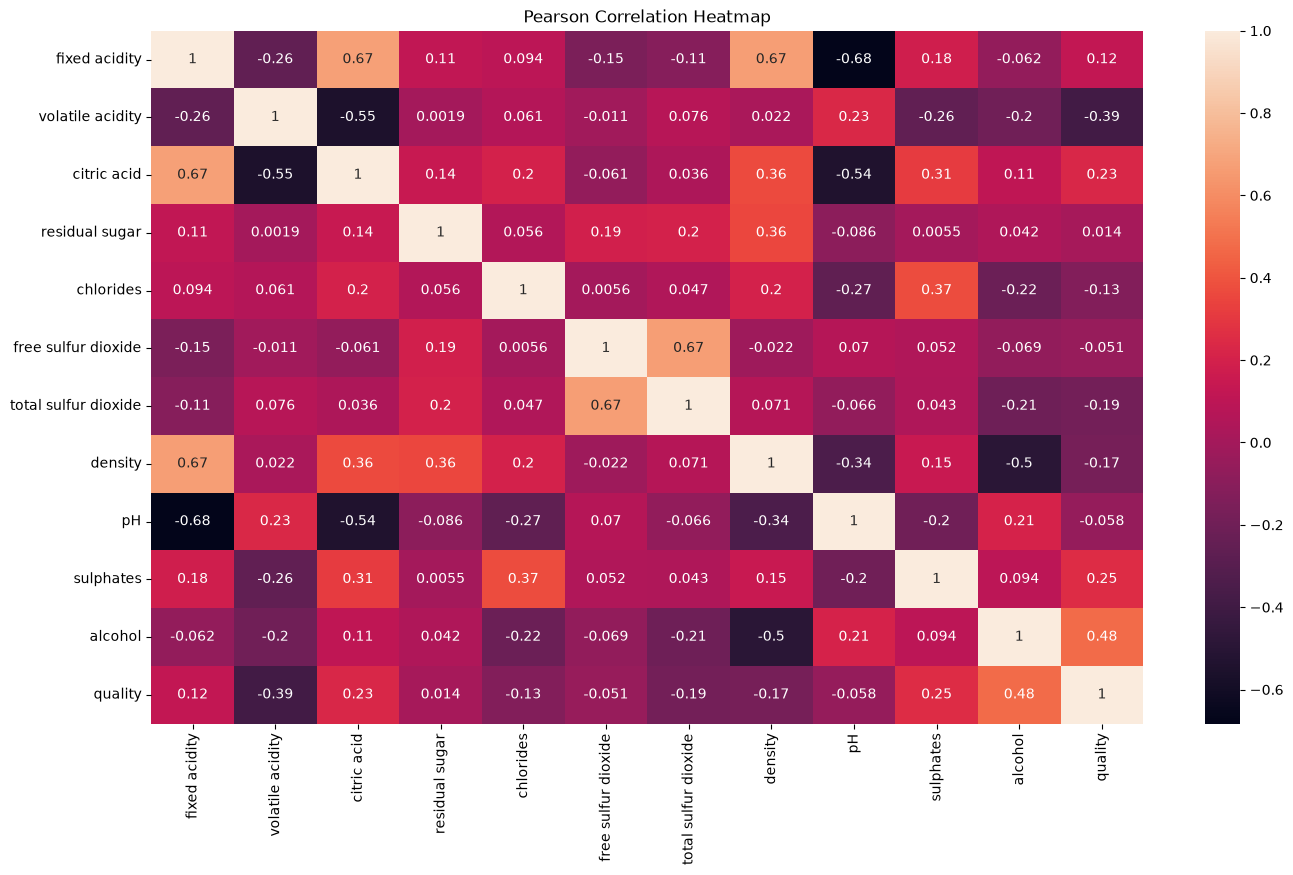

In [24]:
print("NguyenDucTinh - 6451071077")

plt.figure(figsize=(16, 9))
sns.heatmap(data.corr(method='pearson', numeric_only=True), annot=True)
plt.title("Pearson Correlation Heatmap")
plt.show()

# CÂU 4: TÁCH FEATURES VÀ LABELS

In [18]:
print("NguyenDucTinh - 6451071077")

features = data.drop('quality', axis=1)
labels = data['quality']

NguyenDucTinh - 6451071077


# CÂU 5: CHUYỂN ĐỔI ONE-HOT VECTOR

In [19]:
print("NguyenDucTinh - 6451071077")

non_numeric_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Các cột dạng chữ (nếu có):", non_numeric_cols)

# Chuyển đổi về dạng one-hot vector (ép kiểu int để hiển thị 0/1 thay vì True/False)
features_onehot = pd.get_dummies(features, columns=non_numeric_cols, dtype=int)
features_onehot

NguyenDucTinh - 6451071077
Các cột dạng chữ (nếu có): Index([], dtype='str')


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2


# CÂU 6: TÁCH DỮ LIỆU HUẤN LUYỆN VÀ KIỂM THỬ

In [20]:
print("NguyenDucTinh - 6451071077")

X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42
)

print("Số lượng dữ liệu huấn luyện (X_train):", len(X_train))
print("Số lượng dữ liệu kiểm thử (X_test):", len(X_test))

NguyenDucTinh - 6451071077
Số lượng dữ liệu huấn luyện (X_train): 1119
Số lượng dữ liệu kiểm thử (X_test): 480


# CÂU 7: XÂY DỰNG CÂY QUYẾT ĐỊNH ID3

NguyenDucTinh - 6451071077
Accuracy (ID3): 0.5979166666666667
Report (ID3):
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.09      0.12      0.10        17
           5       0.71      0.67      0.69       195
           6       0.61      0.62      0.62       200
           7       0.46      0.46      0.46        61
           8       0.33      0.33      0.33         6

    accuracy                           0.60       480
   macro avg       0.37      0.37      0.37       480
weighted avg       0.61      0.60      0.60       480



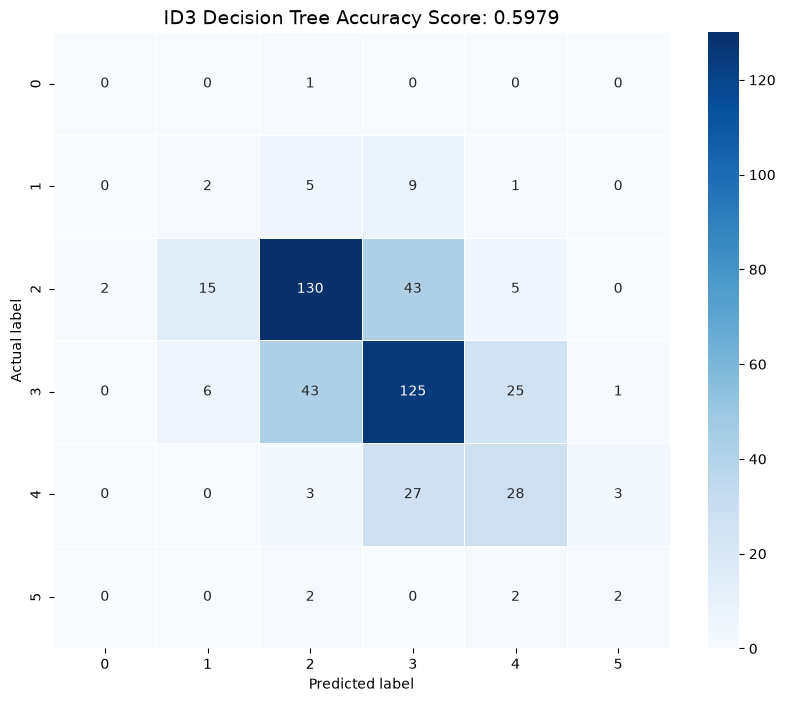

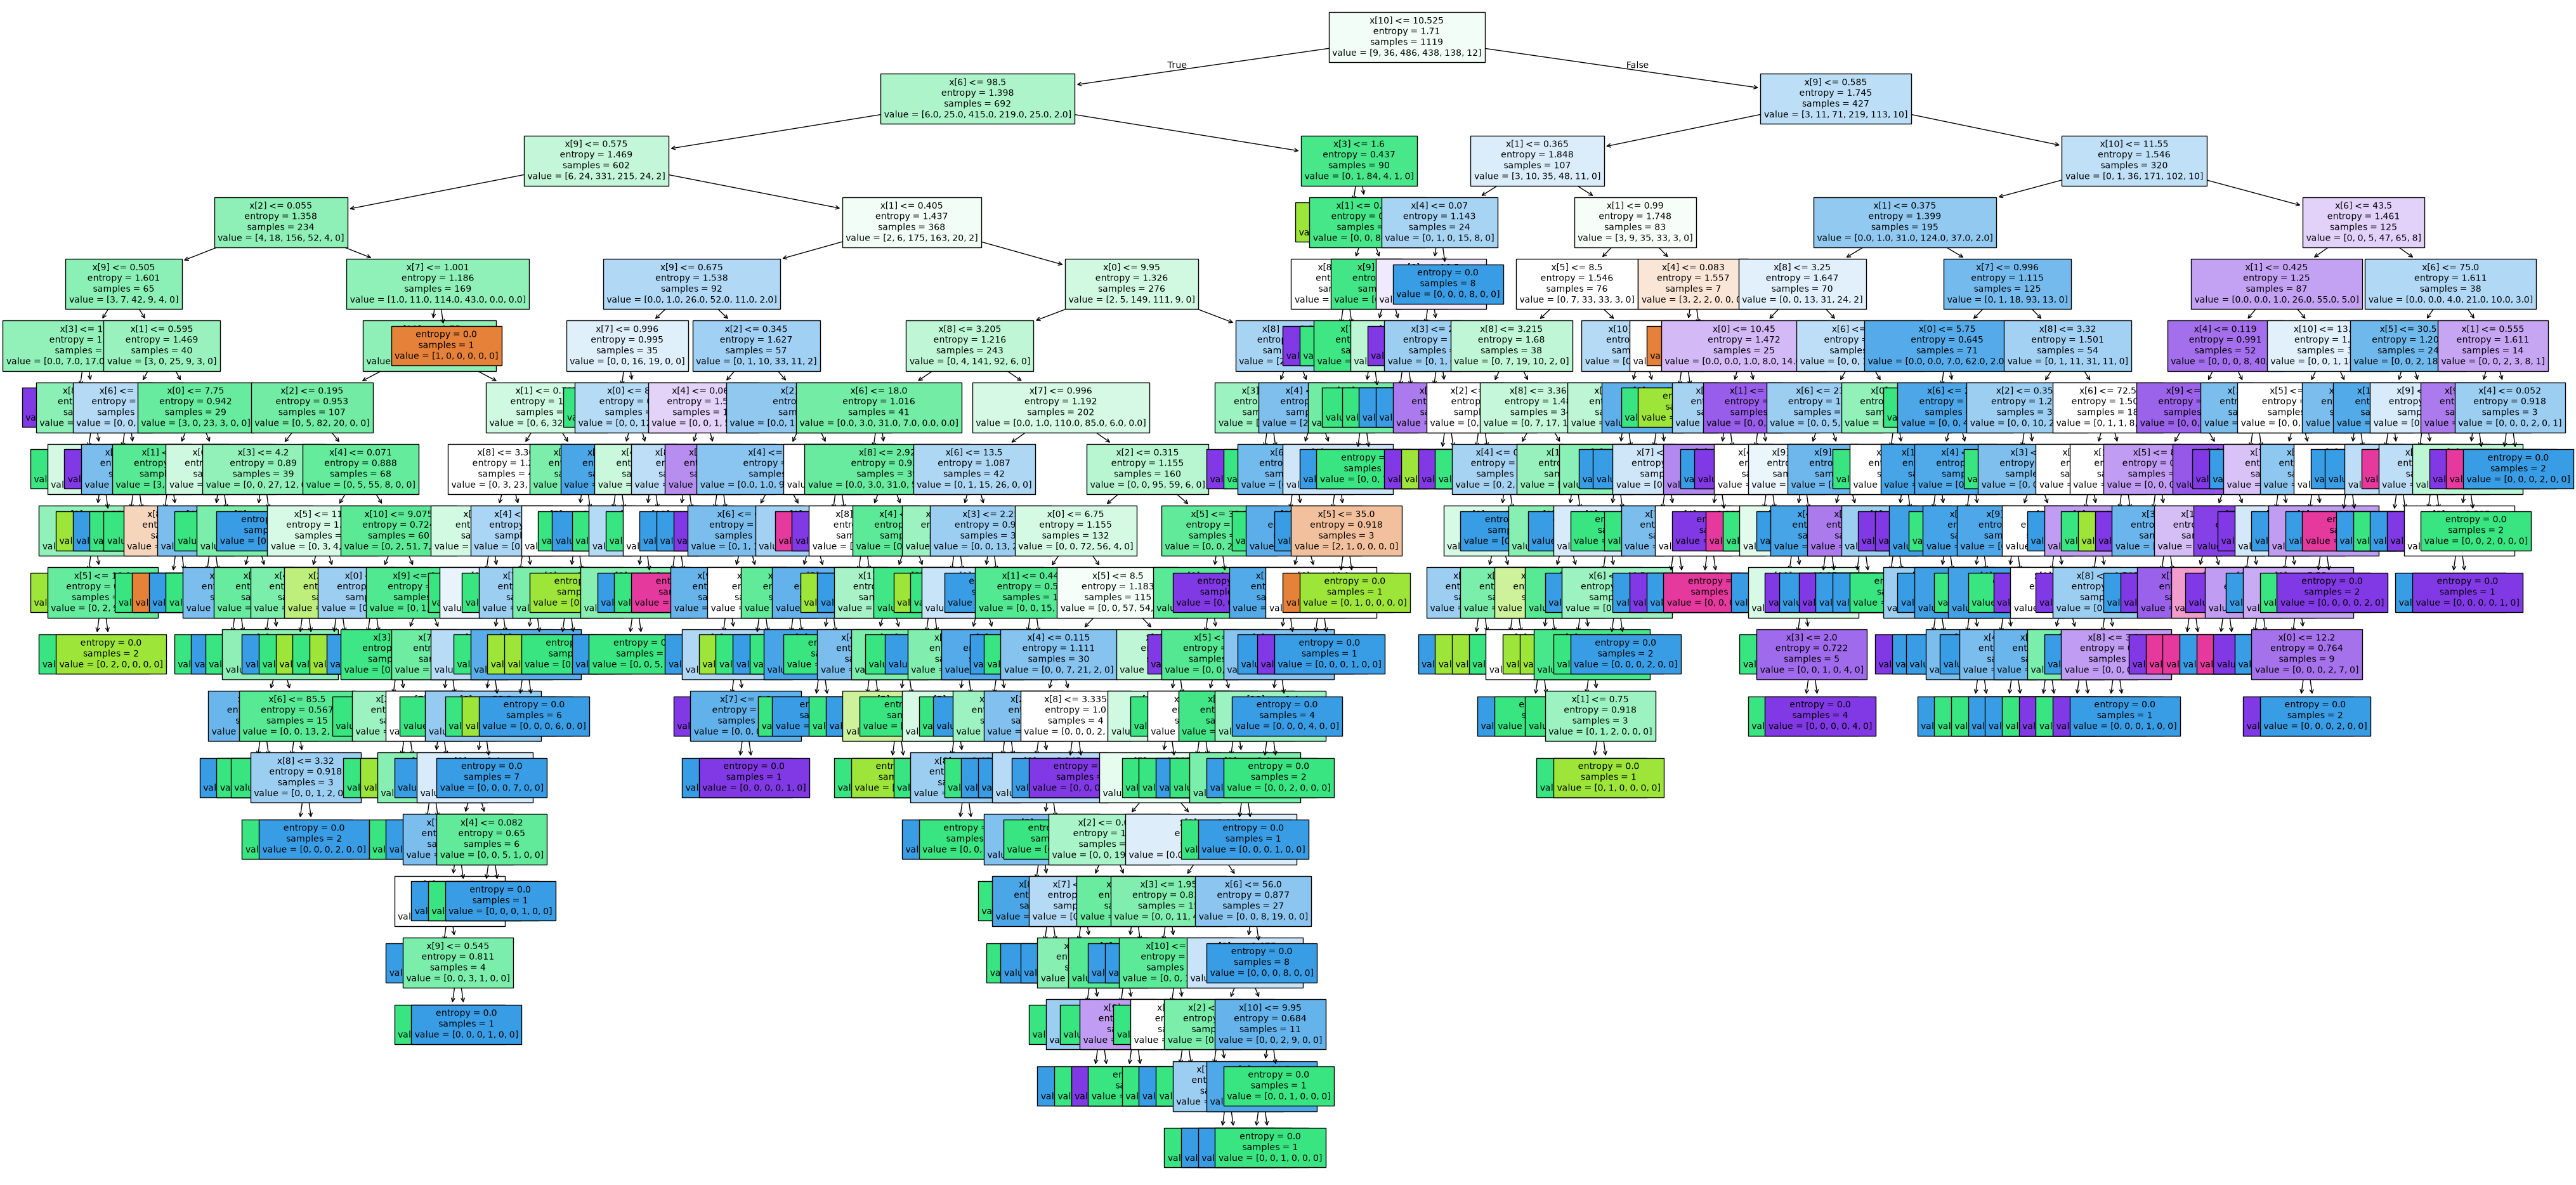

In [21]:
print("NguyenDucTinh - 6451071077")

# Huấn luyện mô hình Cây quyết định ID3 (criterion='entropy')
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
clf_id3.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
id3_pred = clf_id3.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)

print("Accuracy (ID3):", id3_score)
print("Report (ID3):\n", metrics.classification_report(y_test, id3_pred, zero_division=0))

# Vẽ ma trận nhầm lẫn (Confusion Matrix)
id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'ID3 Decision Tree Accuracy Score: {id3_score:.4f}', size=14)
plt.show()

# Biểu diễn và lưu cấu trúc cây quyết định
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_id3, filled=True, fontsize=10)
plt.savefig('decision_tree.png', dpi=100)
plt.show()

# CÂU 8: XÂY DỰNG CÂY QUYẾT ĐỊNH CART

NguyenDucTinh - 6451071077
Accuracy (CART): 0.5729166666666666
Report (CART):
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.66      0.65      0.65       195
           6       0.57      0.60      0.59       200
           7       0.46      0.43      0.44        61
           8       0.33      0.17      0.22         6

    accuracy                           0.57       480
   macro avg       0.35      0.32      0.33       480
weighted avg       0.57      0.57      0.57       480



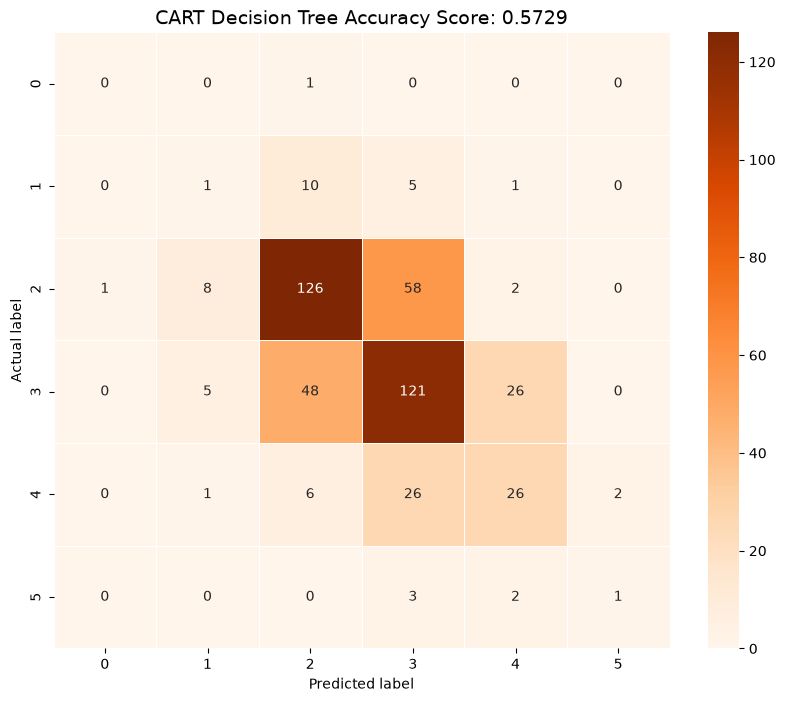

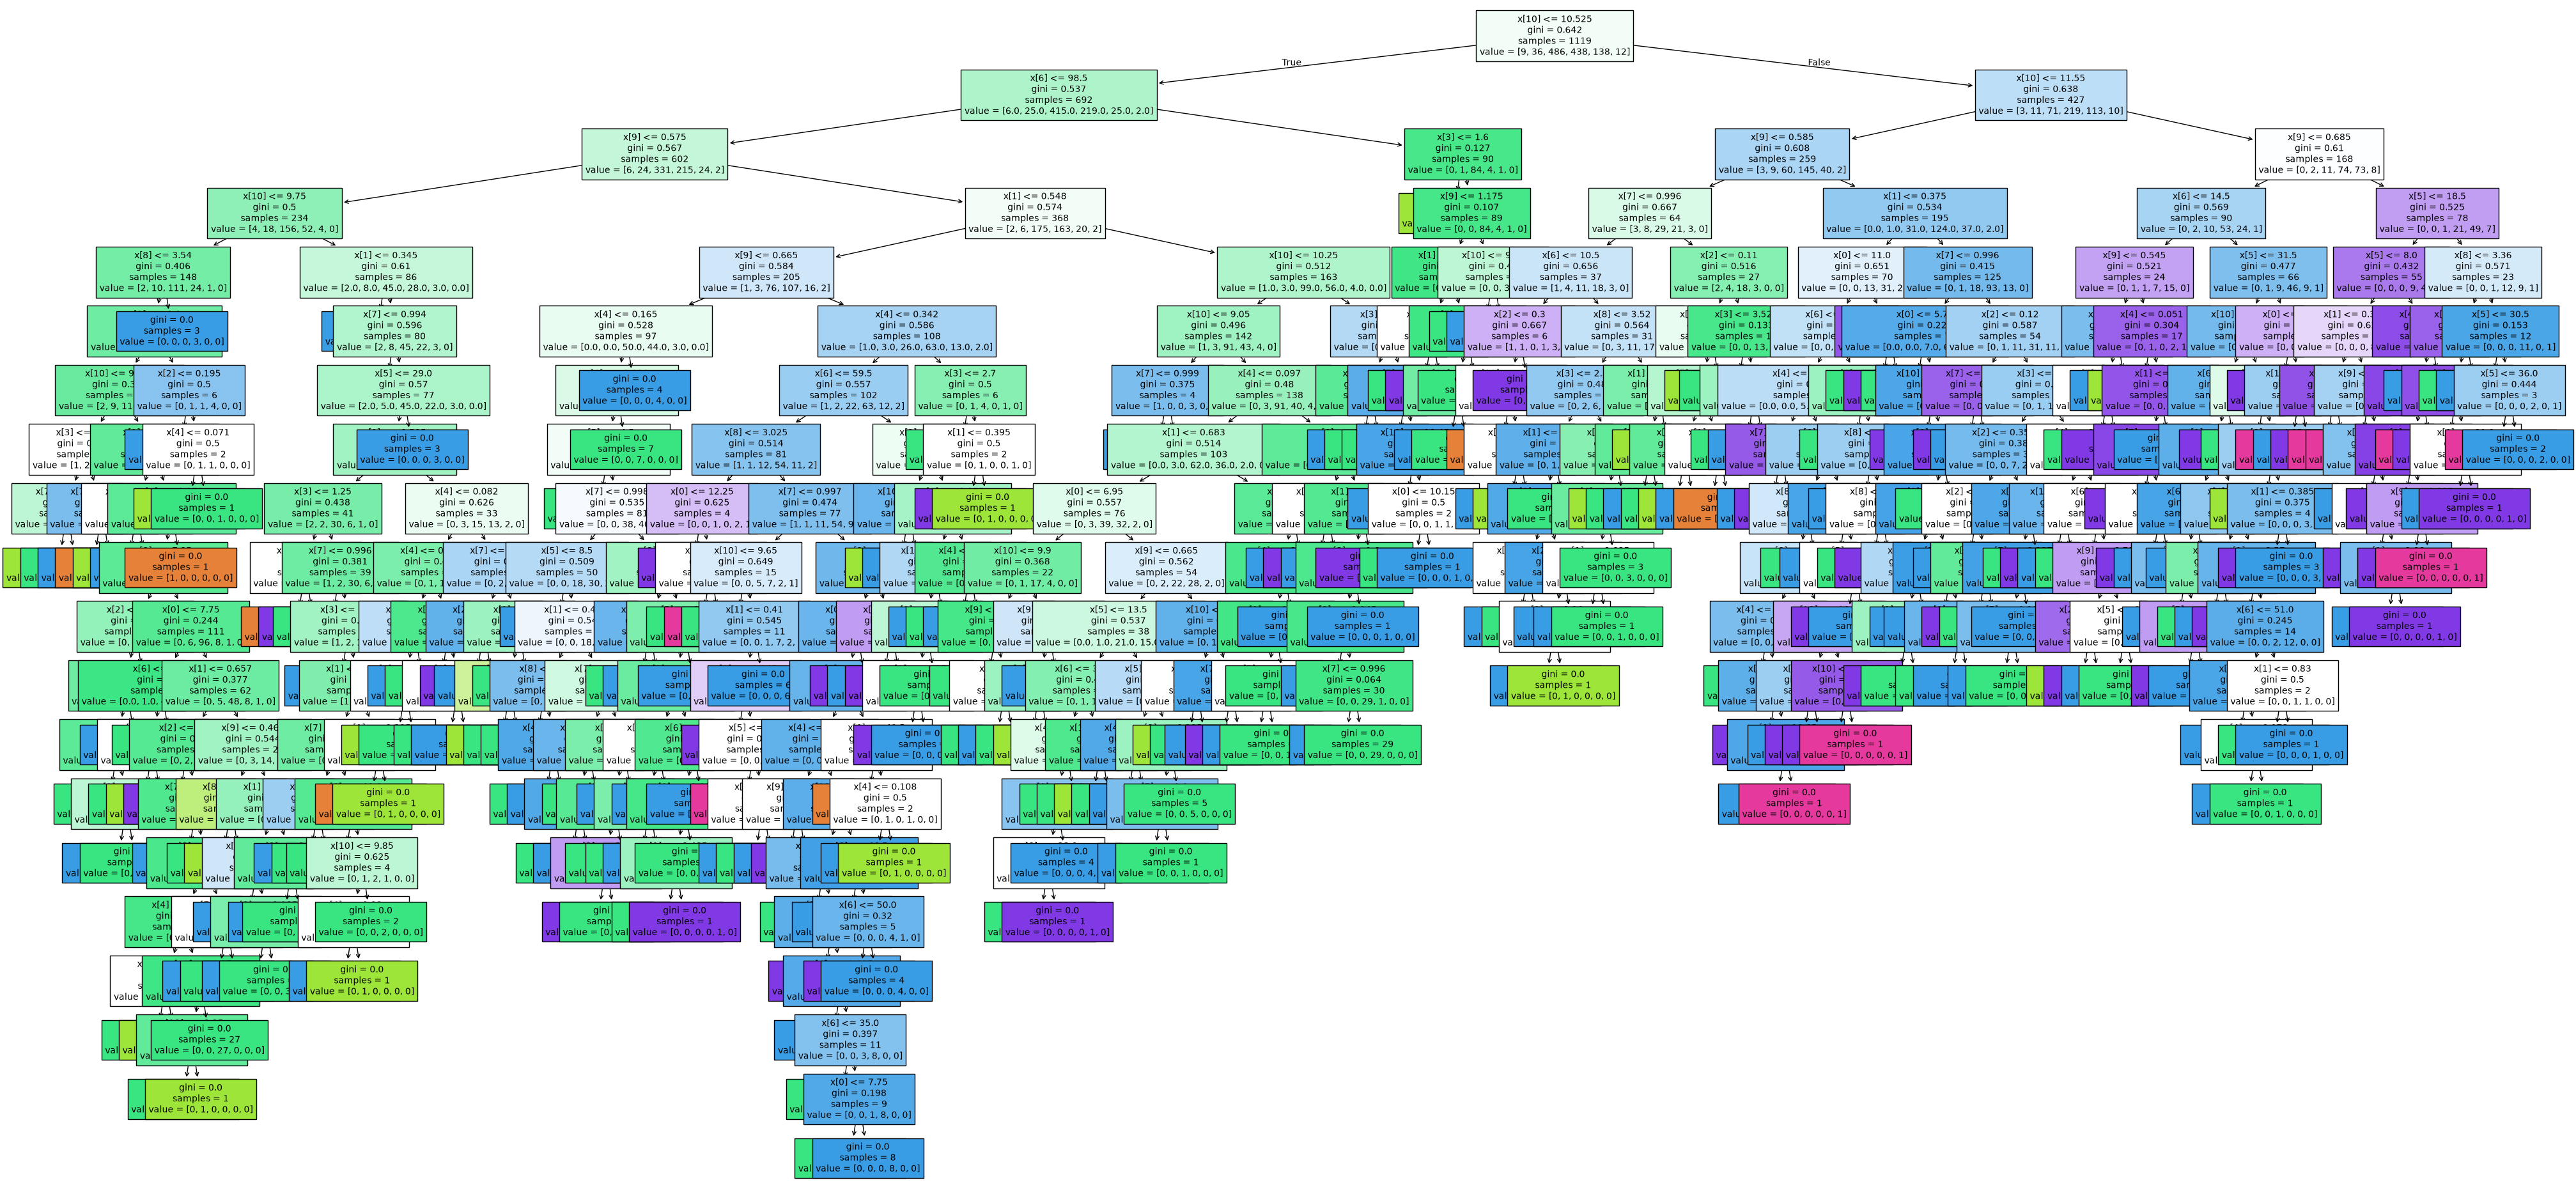

In [22]:
print("NguyenDucTinh - 6451071077")

# Huấn luyện mô hình Cây quyết định CART (criterion='gini')
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
clf_cart.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print("Accuracy (CART):", cart_score)
print("Report (CART):\n", metrics.classification_report(y_test, cart_pred, zero_division=0))

# Vẽ ma trận nhầm lẫn cho CART
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Oranges')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'CART Decision Tree Accuracy Score: {cart_score:.4f}', size=14)
plt.show()

# Biểu diễn và lưu cấu trúc cây quyết định CART
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_cart, filled=True, fontsize=10)
plt.savefig('decision_tree.png', dpi=100)
plt.show()

# CÂU 9: XÂY DỰNG MÔ HÌNH NAIVE BAYES

NguyenDucTinh - 6451071077
Accuracy (Naïve Bayes): 0.5416666666666666
Report (Naïve Bayes):
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



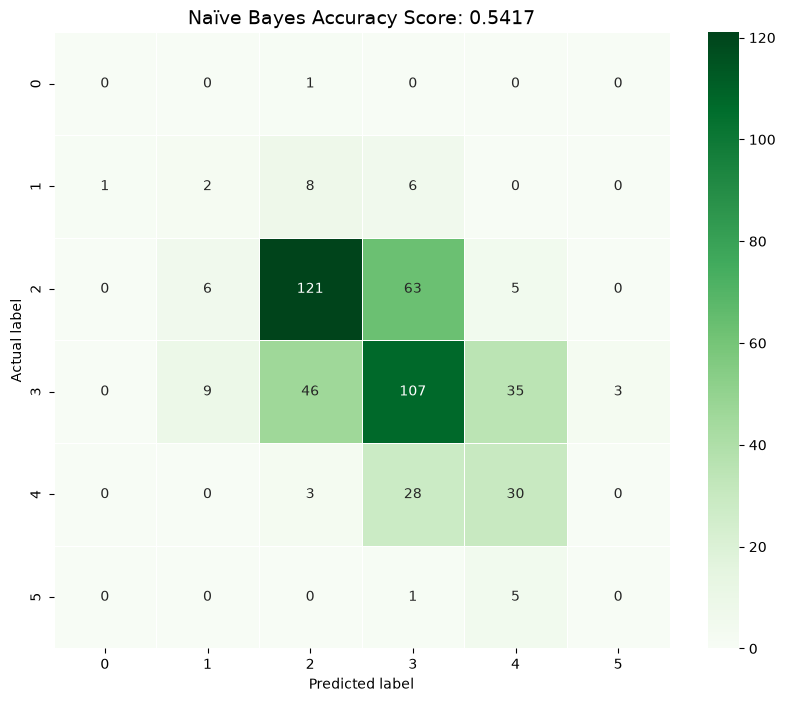

In [23]:
print("NguyenDucTinh - 6451071077")

# Huấn luyện mô hình Naïve Bayes
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)
bayes_score = metrics.accuracy_score(y_test, bayes_pred)

print("Accuracy (Naïve Bayes):", bayes_score)
print("Report (Naïve Bayes):\n", metrics.classification_report(y_test, bayes_pred, zero_division=0))

# Vẽ ma trận nhầm lẫn cho Naïve Bayes
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naïve Bayes Accuracy Score: {bayes_score:.4f}', size=14)
plt.show()